# Baseline PM2.5 Fontibón — LSTM, 2 fases de tratamiento de datos faltantes

Este cuaderno es la variante **LSTM** del baseline de Random Forest. Se mantiene el mismo
diseño experimental de fondo (mismo target, misma ventana temporal, mismo split, mismas reglas
anti-fuga de información), pero:

- El modelo pasa de **Random Forest tabular** a **LSTM secuencial** (backend PyTorch, construido
  en la Sección 3 de este cuaderno).
- En vez de las 4 filas del baseline original (persistencia + 3 fases de imputación), aquí se
  comparan **exactamente 2 fases**, que son las dos que capturan la pregunta de investigación
  central — "¿ayuda imputar con información espacial (grafo de estaciones vecinas) frente a no
  imputar en absoluto?":

| Fase | Estrategia | Rol |
|---|---|---|
| A | FONTIBÓN, solo variables con cobertura nativa suficiente (**sin imputar**) | Control / piso — LSTM con datos 100% reales |
| B | FONTIBÓN + MissForest + vecinos vía grafo de distancia (**con imputación por grafo**) | ¿Ayuda la imputación espacial frente a no imputar? |

## Reglas que se respetan en todo el cuaderno (no negociables, heredadas del baseline RF)

1. **Split temporal, no aleatorio**: train = 2020-01-01 a 2023-12-31, test = 2024 completo
   (año-independiente, igual protocolo que el paper de referencia en Beijing).
2. **El imputador (MissForest) se ajusta *solo* con el período de train** y se aplica hacia
   adelante sobre test — nunca se ajusta con el dataset completo (evita fuga de información).
3. **El escalador (StandardScaler) se ajusta solo con train** — tanto el de features como el
   del target. Esto es nuevo respecto al baseline RF (que no necesitaba escalar) y es
   obligatorio para LSTM: las redes recurrentes entrenan mal con features en escalas muy
   distintas (p. ej. PM2.5 en µg/m³ vs. presión en hPa).
4. **El target de evaluación (PM2.5 de test) es siempre el valor real observado, nunca un valor
   imputado.** Si una hora de test tiene el PM2.5 faltante, esa hora se excluye de la
   evaluación, no se rellena para evaluarla.
5. **La parada temprana (early stopping) usa un recorte cronológico del final del período de
   train como validación** — nunca una partición aleatoria (eso mezclaría información del
   futuro cercano al test dentro de la señal usada para decidir cuándo parar de entrenar).
6. Se miden y separan tres tiempos por fase: tiempo de imputación, tiempo de entrenamiento del
   LSTM, y tiempo de inferencia.

## Supuesto explícito de alcance

El baseline RF original comparaba 4 filas (persistencia + 3 fases). Este cuaderno se limita, a
pedido, a **2 fases de LSTM** — no se repite aquí la línea base de persistencia. Si se quiere
esa comparación de nuevo (persistencia vs. LSTM), es un cálculo de una celda (ver el pipeline
de la Sección 5, no necesita imputación ni entrenamiento) y se puede agregar sin tocar el resto
del cuaderno.


---

## Sección 1: Librerías, backend y parámetros globales

**Qué se hace:** se importan las librerías (incluyendo PyTorch, que es el backend elegido para
el LSTM — ver justificación abajo) y se fijan en un solo lugar todos los parámetros que deben
mantenerse iguales entre las dos fases.

**Por qué PyTorch como backend:** el entorno de referencia (Colab) trae PyTorch preinstalado,
tiene soporte de GPU sin configuración adicional, y su API de `Dataset`/`DataLoader` encaja
naturalmente con el patrón de "ventanas deslizantes" que ya usa este proyecto. Si el entorno de
ejecución no tiene GPU, el cuaderno cae automáticamente a CPU sin cambiar una sola línea de
código (ver `DISPOSITIVO` más abajo).

In [1]:
import os
import gc
import time
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import ExtraTreesRegressor
from sklearn.experimental import enable_iterative_imputer  # necesario para habilitar IterativeImputer
from sklearn.impute import IterativeImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

sns.set_style('whitegrid')

# ── Utilidades de memoria (igual que el baseline RF) ────────────────────────
try:
    import psutil
    def reportar_ram(etiqueta=''):
        uso = psutil.virtual_memory()
        print(f'[RAM{" - " + etiqueta if etiqueta else ""}] '
              f'{uso.used/1e9:.2f} GB usados / {uso.total/1e9:.2f} GB totales '
              f'({uso.percent:.0f}%)')
except ImportError:
    def reportar_ram(etiqueta=''):
        pass


def liberar(*nombres_variables):
    """Borra del namespace global las variables cuyo nombre se pase (si existen)
    y fuerza recolección de basura. Se usa entre fases para no acumular en RAM
    dataframes/tensores intermedios que ya cumplieron su función."""
    for nombre in nombres_variables:
        if nombre in globals():
            del globals()[nombre]
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


DISPOSITIVO = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Librerías cargadas correctamente.')
print(f'Backend LSTM: PyTorch {torch.__version__} — dispositivo: {DISPOSITIVO}')
reportar_ram('inicio del cuaderno')


Librerías cargadas correctamente.
Backend LSTM: PyTorch 2.13.0 — dispositivo: cpu
[RAM - inicio del cuaderno] 3.75 GB usados / 8.23 GB totales (46%)


In [3]:
# ── Parámetros globales — fijos para las 2 fases (heredados del baseline RF) ──

# Rutas portables: localiza el parquet tanto si el kernel inicia en la raíz
# del repositorio como si inicia dentro de `modelos y bd`.
from pathlib import Path

NOMBRE_PARQUET = 'bogota_calidad_aire_raw.parquet'
_carpetas_busqueda = (Path.cwd(), *Path.cwd().parents)
_candidatos_parquet = [
    candidato
    for carpeta in _carpetas_busqueda
    for candidato in (carpeta / NOMBRE_PARQUET, carpeta / 'modelos y bd' / NOMBRE_PARQUET)
    if candidato.is_file()
]
if not _candidatos_parquet:
    raise FileNotFoundError(
        f'No se encontró {NOMBRE_PARQUET}. Abre el cuaderno desde el repositorio o coloca el archivo en modelos y bd.'
    )
RUTA_PARQUET = str(_candidatos_parquet[0])


ESTACION_OBJETIVO = 'FONTIBÓN'

FECHA_INICIO = '2020-01-01'
FECHA_FIN_EXCLUSIVA = '2025-01-01'   # límite exclusivo, cubre hasta 2024-12-31 23:00
FECHA_CORTE_TRAIN_TEST = '2024-01-01'   # train: [FECHA_INICIO, FECHA_CORTE); test: [FECHA_CORTE, FECHA_FIN)

LOOKBACK = 24          # ventana de lags/timesteps, igual que el baseline RF (h1: 1 paso adelante)
VARIABLES_REPLICA = ['PM2.5', 'TAire2', 'TAire10', 'HAire2', 'HAire10',
                      'P', 'DViento', 'VViento', 'PLiquida']

# Umbral de cobertura nativa (Fase A): variables con menos de este % de horas observadas
# en el período de TRAIN se descartan del feature set, en vez de imputarse.
UMBRAL_COBERTURA_FASE_A = 0.70

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

print(f'Estación objetivo: {ESTACION_OBJETIVO}')
print(f'Train: [{FECHA_INICIO}, {FECHA_CORTE_TRAIN_TEST})')
print(f'Test:  [{FECHA_CORTE_TRAIN_TEST}, {FECHA_FIN_EXCLUSIVA})')

# ── Parámetros del imputador (MissForest, solo Fase B) — idénticos al baseline RF ──
N_ESTIMATORS_IMPUTER = 15
MAX_DEPTH_IMPUTER = 10
MAX_ITER_IMPUTER = 3
N_NEAREST_FEATURES_IMPUTER = 12
IMPUTER_N_JOBS = 1
MUESTRA_FIT_IMPUTADOR = 8000   # None = usar todo el train (más lento)
TIPO_ESTIMADOR_IMPUTADOR = 'extra_trees'
K_VECINOS = 3   # estaciones vecinas más cercanas usadas en el grafo de distancia

# La caché queda junto al dataset, dentro del proyecto actual.
CACHE_DIR = str(Path(RUTA_PARQUET).parent / 'cache_imputacion_lstm')
os.makedirs(CACHE_DIR, exist_ok=True)
RUTA_CACHE_FASE_B = os.path.join(CACHE_DIR, 'fase_b_imputado.parquet')


def construir_estimador_imputador():
    parametros = dict(
        n_estimators=N_ESTIMATORS_IMPUTER,
        max_depth=MAX_DEPTH_IMPUTER,
        random_state=RANDOM_STATE,
        n_jobs=IMPUTER_N_JOBS,
    )
    if TIPO_ESTIMADOR_IMPUTADOR == 'extra_trees':
        return ExtraTreesRegressor(**parametros)
    from sklearn.ensemble import RandomForestRegressor
    return RandomForestRegressor(**parametros)


# ── Hiperparámetros del LSTM — comunes a las 2 fases ────────────────────────
# (mantener iguales entre fases es tan importante como mantener igual el RF en
# el baseline original: cualquier diferencia de desempeño debe venir de los
# DATOS, no de que una fase tuvo una red más grande o entrenó más épocas.)
HIDDEN_SIZE = 64
NUM_LAYERS = 2
DROPOUT = 0.2
BATCH_SIZE = 256
LEARNING_RATE = 1e-3
MAX_EPOCHS = 60
PACIENCIA_EARLY_STOPPING = 6     # épocas sin mejora en validación antes de parar
FRACCION_VALIDACION = 0.10       # último 10% cronológico del TRAIN, para early stopping

print(f'LSTM: hidden={HIDDEN_SIZE}, layers={NUM_LAYERS}, dropout={DROPOUT}, '
      f'batch={BATCH_SIZE}, lr={LEARNING_RATE}, max_epochs={MAX_EPOCHS}, '
      f'paciencia={PACIENCIA_EARLY_STOPPING}')


Estación objetivo: FONTIBÓN
Train: [2020-01-01, 2024-01-01)
Test:  [2024-01-01, 2025-01-01)
LSTM: hidden=64, layers=2, dropout=0.2, batch=256, lr=0.001, max_epochs=60, paciencia=6


---

## Sección 2: Carga y pivote largo → ancho

Idéntico al baseline RF: se carga el parquet crudo, se filtra a las variables de la réplica, y
se define `pivotear_ancho`, la misma función reutilizable para pivotar cualquier subconjunto de
estaciones a formato ancho (una fila por hora, una columna por variable×estación).

In [4]:
t0 = time.perf_counter()
df_raw = pd.read_parquet(RUTA_PARQUET)
print(f'Parquet cargado: {len(df_raw):,} filas en {time.perf_counter()-t0:.1f}s')

df_raw['med_fecha_inicio'] = pd.to_datetime(df_raw['med_fecha_inicio'])
df_raw['med_concentracion_estandar'] = pd.to_numeric(
    df_raw['med_concentracion_estandar'], errors='coerce'
)

df = df_raw[df_raw['msfl_code'].isin(VARIABLES_REPLICA)].copy()
del df_raw
print(f'Filas tras filtrar a variables de la réplica: {len(df):,}')


Parquet cargado: 8,011,058 filas en 2.1s
Filas tras filtrar a variables de la réplica: 4,172,687


In [5]:
def pivotear_ancho(df_largo, estaciones, fecha_inicio, fecha_fin_exclusiva):
    """
    Convierte el formato largo (fila = medición) a formato ancho, reindexado a
    una grilla horaria continua, para una o varias estaciones.

    Si se pasa más de una estación, las columnas de las estaciones "vecinas"
    (todas menos la primera de la lista) se prefijan con el nombre de la
    estación, para no confundirlas con las variables de la estación objetivo.
    """
    grilla = pd.date_range(fecha_inicio, fecha_fin_exclusiva, freq='h', inclusive='left')
    tablas = []
    for i, est in enumerate(estaciones):
        sub = df_largo[df_largo['nombre_est'] == est].copy()
        sub = sub[(sub['med_fecha_inicio'] >= fecha_inicio) &
                   (sub['med_fecha_inicio'] < fecha_fin_exclusiva)]

        ancha = sub.pivot_table(
            index='med_fecha_inicio', columns='msfl_code',
            values='med_concentracion_estandar', aggfunc='mean'
        )
        ancha = ancha.reindex(grilla)

        if i > 0:
            ancha.columns = [f'{est}__{c}' for c in ancha.columns]

        tablas.append(ancha)

    resultado = pd.concat(tablas, axis=1)
    resultado.index.name = 'fecha_hora'
    resultado = resultado.astype('float32')
    return resultado


df_ancho_fontibon = pivotear_ancho(df, [ESTACION_OBJETIVO], FECHA_INICIO, FECHA_FIN_EXCLUSIVA)
print('Forma de la tabla ancha de FONTIBÓN:', df_ancho_fontibon.shape)
df_ancho_fontibon.head()


Forma de la tabla ancha de FONTIBÓN: (43848, 9)


msfl_code,DViento,HAire10,HAire2,P,PLiquida,PM2.5,TAire10,TAire2,VViento
fecha_hora,,,,,,,,,
2020-01-01 00:00:00,232.0,86.0,NaN,NaN,NaN,NaN,12.6,NaN,1.9
2020-01-01 01:00:00,222.0,86.0,NaN,NaN,NaN,47.700001,12.5,NaN,1.8
2020-01-01 02:00:00,330.0,87.0,NaN,NaN,NaN,36.099998,12.1,NaN,1.9
2020-01-01 03:00:00,7.0,90.0,NaN,NaN,NaN,34.000000,11.1,NaN,2.7
2020-01-01 04:00:00,2.0,91.0,NaN,NaN,NaN,39.900002,11.2,NaN,0.8


---

## Sección 3: Construcción de secuencias (ventanas 3D) y split temporal

**Diferencia clave frente al baseline RF:** el RF tabular usaba una fila por hora con columnas
`variable_lag1 ... variable_lag24` (features "planas"). El LSTM necesita, en cambio, un tensor
3D `(n_muestras, lookback, n_variables)` — cada muestra es una secuencia ordenada de 24 horas,
no un vector de lags aplanado. `construir_secuencias` hace exactamente esa transformación,
manteniendo el mismo `lookback=24` y el mismo objetivo (`PM2.5` en el instante `t`, usando las
24 horas anteriores `t-24 ... t-1` de todas las variables).

**Regla importante (heredada):** el split se hace por fecha del instante objetivo `t`, antes de
imputar/escalar — acá solo se recorta, no se toca el contenido todavía.

In [6]:
def construir_secuencias(df_ancho, columnas, columna_objetivo='PM2.5', lookback=LOOKBACK):
    """
    Construye ventanas deslizantes de tamaño `lookback` sobre `columnas`.

    Devuelve:
      X: np.ndarray float32, forma (n_muestras, lookback, n_columnas) — la
         secuencia de horas t-lookback ... t-1 para cada variable.
      y: np.ndarray float32, forma (n_muestras,) — PM2.5 en el instante t
         (mismo instante que predice el RF: pronóstico a 1h, h1).
      idx_objetivo: DatetimeIndex, el instante t de cada muestra (para poder
         alinear con fechas reales al hacer el split y la evaluación).

    NO elimina NaN — eso se decide después, según la fase (idéntico criterio
    al `construir_features_ventana` del baseline RF).
    """
    arr = df_ancho[columnas].to_numpy(dtype='float32')
    n_filas, n_col = arr.shape
    n_muestras = n_filas - lookback
    if n_muestras <= 0:
        raise ValueError('lookback mayor que el número de filas disponibles.')

    X = np.empty((n_muestras, lookback, n_col), dtype='float32')
    for i in range(n_muestras):
        X[i] = arr[i:i + lookback]

    y = df_ancho[columna_objetivo].to_numpy(dtype='float32')[lookback:]
    idx_objetivo = df_ancho.index[lookback:]
    return X, y, idx_objetivo


def dividir_train_test_secuencias(X, y, idx_objetivo, fecha_corte):
    en_train = idx_objetivo < pd.Timestamp(fecha_corte)
    en_test = ~en_train
    return (X[en_train], y[en_train], idx_objetivo[en_train],
            X[en_test], y[en_test], idx_objetivo[en_test])


print('Funciones de secuenciado y split definidas.')


Funciones de secuenciado y split definidas.


---

## Sección 4: Backend del LSTM (PyTorch) — Dataset, modelo, entrenamiento

Esta sección es el "backend" que reemplaza a `RandomForestRegressor` del baseline anterior.
Se construye una sola vez y se reutiliza sin cambios en las dos fases (misma disciplina que
`construir_features_ventana`/`evaluar_y_registrar` en el baseline RF: un solo lugar donde vive
la lógica, para que ninguna fase entrene "un poco distinto" por accidente).

**Piezas:**
1. `SecuenciaDataset` — envuelve los arrays `(X, y)` como `torch.utils.data.Dataset`.
2. `LSTMPronosticador` — LSTM apilado (`NUM_LAYERS` capas) + capa lineal de salida, que toma la
   última salida temporal de la secuencia y la mapea a una predicción escalar de PM2.5.
3. `entrenar_lstm` — bucle de entrenamiento con **early stopping cronológico**: separa el último
   `FRACCION_VALIDACION` del train (en el tiempo, no al azar) como validación, entrena hasta
   `MAX_EPOCHS` o hasta `PACIENCIA_EARLY_STOPPING` épocas sin mejora en la pérdida de
   validación, y al final restaura los pesos de la mejor época (no los últimos).
4. `predecir_lstm` — inferencia en modo `eval()`, sin gradientes.

In [8]:
class SecuenciaDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.from_numpy(X).float()
        self.y = torch.from_numpy(y).float()

    def __len__(self):
        return len(self.X)

    def __getitem__(self, i):
        return self.X[i], self.y[i]


class LSTMPronosticador(nn.Module):
    def __init__(self, n_features, hidden_size=HIDDEN_SIZE, num_layers=NUM_LAYERS, dropout=DROPOUT):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=n_features,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0,
        )
        self.cabeza = nn.Sequential(
            nn.Linear(hidden_size, hidden_size // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_size // 2, 1),
        )

    def forward(self, x):
        # x: (batch, lookback, n_features)
        salidas, _ = self.lstm(x)
        ultimo_paso = salidas[:, -1, :]   # (batch, hidden_size) — estado tras ver toda la ventana
        return self.cabeza(ultimo_paso).squeeze(-1)


def _partir_train_val_cronologico(X_train, y_train, fraccion_val):
    """Separa el final cronológico del train para validación de early stopping.
    Las muestras ya vienen ordenadas por tiempo (construir_secuencias no baraja
    nada), así que un corte por posición equivale a un corte por fecha."""
    n = len(X_train)
    n_val = max(1, int(round(n * fraccion_val)))
    corte = n - n_val
    return X_train[:corte], y_train[:corte], X_train[corte:], y_train[corte:]


def entrenar_lstm(X_train, y_train, nombre_fase, n_features):
    """Entrena un LSTMPronosticador con early stopping cronológico.

    Devuelve: (modelo entrenado con los MEJORES pesos, historial dict con
    'train_loss'/'val_loss' por época, tiempo total de entrenamiento en segundos).
    """
    X_tr, y_tr, X_val, y_val = _partir_train_val_cronologico(X_train, y_train, FRACCION_VALIDACION)
    print(f'[{nombre_fase}] train efectivo: {len(X_tr):,} muestras | '
          f'validación (early stopping): {len(X_val):,} muestras')

    dl_train = DataLoader(SecuenciaDataset(X_tr, y_tr), batch_size=BATCH_SIZE, shuffle=True)
    dl_val = DataLoader(SecuenciaDataset(X_val, y_val), batch_size=BATCH_SIZE, shuffle=False)

    modelo = LSTMPronosticador(n_features=n_features).to(DISPOSITIVO)
    optimizador = torch.optim.Adam(modelo.parameters(), lr=LEARNING_RATE)
    criterio = nn.MSELoss()

    mejor_val_loss = float('inf')
    mejor_estado = None
    epocas_sin_mejora = 0
    historial = {'train_loss': [], 'val_loss': []}

    t0 = time.perf_counter()
    for epoca in range(1, MAX_EPOCHS + 1):
        modelo.train()
        perdida_train_acum = 0.0
        for xb, yb in dl_train:
            xb, yb = xb.to(DISPOSITIVO), yb.to(DISPOSITIVO)
            optimizador.zero_grad()
            pred = modelo(xb)
            perdida = criterio(pred, yb)
            perdida.backward()
            optimizador.step()
            perdida_train_acum += perdida.item() * len(xb)
        perdida_train = perdida_train_acum / len(dl_train.dataset)

        modelo.eval()
        perdida_val_acum = 0.0
        with torch.no_grad():
            for xb, yb in dl_val:
                xb, yb = xb.to(DISPOSITIVO), yb.to(DISPOSITIVO)
                pred = modelo(xb)
                perdida_val_acum += criterio(pred, yb).item() * len(xb)
        perdida_val = perdida_val_acum / len(dl_val.dataset)

        historial['train_loss'].append(perdida_train)
        historial['val_loss'].append(perdida_val)

        if perdida_val < mejor_val_loss - 1e-6:
            mejor_val_loss = perdida_val
            mejor_estado = {k: v.detach().cpu().clone() for k, v in modelo.state_dict().items()}
            epocas_sin_mejora = 0
        else:
            epocas_sin_mejora += 1

        if epoca == 1 or epoca % 5 == 0 or epocas_sin_mejora == 0:
            print(f'  época {epoca:>3d}/{MAX_EPOCHS} — '
                  f'train_loss={perdida_train:.4f}  val_loss={perdida_val:.4f}'
                  f'{"  <- mejor" if epocas_sin_mejora == 0 else ""}')

        if epocas_sin_mejora >= PACIENCIA_EARLY_STOPPING:
            print(f'  early stopping en época {epoca} '
                  f'({PACIENCIA_EARLY_STOPPING} épocas sin mejora en validación).')
            break

    tiempo_entrenamiento = time.perf_counter() - t0

    if mejor_estado is not None:
        modelo.load_state_dict(mejor_estado)
    print(f'[{nombre_fase}] entrenamiento: {tiempo_entrenamiento:.1f}s, '
          f'mejor val_loss={mejor_val_loss:.4f}')
    return modelo, historial, tiempo_entrenamiento


def predecir_lstm(modelo, X):
    modelo.eval()
    dl = DataLoader(SecuenciaDataset(X, np.zeros(len(X), dtype='float32')),
                     batch_size=BATCH_SIZE, shuffle=False)
    preds = []
    t0 = time.perf_counter()
    with torch.no_grad():
        for xb, _ in dl:
            xb = xb.to(DISPOSITIVO)
            preds.append(modelo(xb).cpu().numpy())
    tiempo_inferencia = time.perf_counter() - t0
    return np.concatenate(preds), tiempo_inferencia


print('Backend LSTM (Dataset, modelo, entrenamiento con early stopping) definido.')


Backend LSTM (Dataset, modelo, entrenamiento con early stopping) definido.


---

## Sección 5: Registro de resultados

Misma función `evaluar_y_registrar` del baseline RF (RMSE vía `sqrt(MSE)` para compatibilidad
entre versiones de scikit-learn, MAE, R²), con dos columnas nuevas: `epocas_entrenadas` y
`mejor_val_loss`, específicas del entrenamiento por épocas del LSTM.

In [9]:
resultados_globales = []


def evaluar_y_registrar(nombre_fase, y_true, y_pred, n_train=np.nan, n_test=np.nan,
                         tiempo_imputacion=0.0, tiempo_entrenamiento=0.0, tiempo_inferencia=0.0,
                         pct_imputado_train=np.nan, epocas_entrenadas=np.nan, mejor_val_loss=np.nan):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)

    resultados_globales.append({
        'fase': nombre_fase,
        'n_train': n_train,
        'n_test': n_test,
        'RMSE': round(rmse, 3),
        'MAE': round(mae, 3),
        'R2': round(r2, 4),
        'tiempo_imputacion_s': round(tiempo_imputacion, 2),
        'tiempo_entrenamiento_s': round(tiempo_entrenamiento, 2),
        'tiempo_inferencia_s': round(tiempo_inferencia, 4),
        'pct_imputado_train': pct_imputado_train,
        'epocas_entrenadas': epocas_entrenadas,
        'mejor_val_loss': mejor_val_loss,
    })
    print(f'[{nombre_fase}] RMSE={rmse:.3f}  MAE={mae:.3f}  R2={r2:.4f}  (n_test={n_test})')
    return rmse, mae, r2


---

## Sección 6: Fase A — LSTM control, sin imputación

**Qué se hace:** idéntico criterio de selección de variables que la Fase 3 del baseline RF: de
las variables disponibles en FONTIBÓN, se conservan solo las que tienen cobertura nativa
suficiente (≥ `UMBRAL_COBERTURA_FASE_A`) **dentro del período de train** — las demás se
descartan del feature set, no se imputan. Se construyen las secuencias, se eliminan las que
tengan algún NaN remanente (en cualquier paso de tiempo o en el target), se escala
(`StandardScaler` ajustado solo con train) y se entrena el LSTM.

**Rol:** el "piso" — cuánto rinde el LSTM usando exclusivamente datos 100% reales, sin ningún
tratamiento estadístico de por medio.

In [10]:
# Cobertura por variable, calculada SOLO con el período de train (evita fuga)
train_fontibon = df_ancho_fontibon.loc[df_ancho_fontibon.index < FECHA_CORTE_TRAIN_TEST]
cobertura_train = train_fontibon.notna().mean().sort_values(ascending=False)
print('Cobertura por variable en TRAIN (FONTIBÓN):')
print((cobertura_train * 100).round(1))

variables_fase_a = cobertura_train[cobertura_train >= UMBRAL_COBERTURA_FASE_A].index.tolist()
if 'PM2.5' not in variables_fase_a:
    variables_fase_a = ['PM2.5'] + variables_fase_a

print(f'\nVariables retenidas en Fase A (cobertura >= {UMBRAL_COBERTURA_FASE_A:.0%}): {variables_fase_a}')


Cobertura por variable en TRAIN (FONTIBÓN):
msfl_code
DViento     99.8
VViento     96.6
PM2.5       88.4
HAire2      74.8
TAire2      74.8
P           60.7
PLiquida    60.7
HAire10     25.0
TAire10     25.0
dtype: float64

Variables retenidas en Fase A (cobertura >= 70%): ['DViento', 'VViento', 'PM2.5', 'HAire2', 'TAire2']


In [11]:
df_fase_a = df_ancho_fontibon[variables_fase_a]

# ── Escalado: se ajusta SOLO con train, se aplica a train y test (regla 3) ──
train_a = df_fase_a.loc[df_fase_a.index < FECHA_CORTE_TRAIN_TEST]

escalador_X_a = StandardScaler().fit(train_a)
escalador_y_a = StandardScaler().fit(train_a[['PM2.5']])

df_fase_a_escalado = pd.DataFrame(
    escalador_X_a.transform(df_fase_a), index=df_fase_a.index, columns=df_fase_a.columns
).astype('float32')

X_a, y_a_escalado, idx_a = construir_secuencias(
    df_fase_a_escalado, variables_fase_a, columna_objetivo='PM2.5', lookback=LOOKBACK
)

(X_train_a, y_train_a, idx_train_a,
 X_test_a, y_test_a_escalado, idx_test_a) = dividir_train_test_secuencias(
    X_a, y_a_escalado, idx_a, FECHA_CORTE_TRAIN_TEST
)

# Sin imputación: se eliminan secuencias con cualquier NaN (en la ventana o en el target)
ok_train_a = ~np.isnan(X_train_a).any(axis=(1, 2)) & ~np.isnan(y_train_a)
X_train_a, y_train_a = X_train_a[ok_train_a], y_train_a[ok_train_a]

ok_test_a = ~np.isnan(X_test_a).any(axis=(1, 2)) & ~np.isnan(y_test_a_escalado)
X_test_a = X_test_a[ok_test_a]
idx_test_a_validos = idx_test_a[ok_test_a]

# El TARGET de evaluación es siempre el valor REAL observado (regla 4), no el escalado/derivado
y_test_a_real = df_ancho_fontibon['PM2.5'].reindex(idx_test_a_validos).to_numpy()

print(f'Fase A — secuencias de train utilizables: {len(X_train_a):,}')
print(f'Fase A — secuencias de test utilizables:  {len(X_test_a):,}')


Fase A — secuencias de train utilizables: 5,869
Fase A — secuencias de test utilizables:  7,039


In [12]:
modelo_a, historial_a, tiempo_train_a = entrenar_lstm(
    X_train_a, y_train_a, nombre_fase='Fase A', n_features=len(variables_fase_a)
)

y_pred_a_escalado, tiempo_inferencia_a = predecir_lstm(modelo_a, X_test_a)

# Invertir el escalado SOLO de las predicciones — y_test_a_real ya está en unidades reales
y_pred_a = escalador_y_a.inverse_transform(y_pred_a_escalado.reshape(-1, 1)).ravel()

epocas_a = len(historial_a['train_loss'])
mejor_val_loss_a = min(historial_a['val_loss'])

evaluar_y_registrar(
    'Fase A - LSTM control (sin imputar)',
    y_test_a_real, y_pred_a,
    n_train=len(X_train_a), n_test=len(X_test_a),
    tiempo_imputacion=0.0,
    tiempo_entrenamiento=tiempo_train_a,
    tiempo_inferencia=tiempo_inferencia_a,
    pct_imputado_train=0.0,
    epocas_entrenadas=epocas_a,
    mejor_val_loss=round(mejor_val_loss_a, 4),
)


[Fase A] train efectivo: 5,282 muestras | validación (early stopping): 587 muestras
  época   1/60 — train_loss=0.7593  val_loss=0.5211  <- mejor
  época   2/60 — train_loss=0.4877  val_loss=0.3602  <- mejor
  época   3/60 — train_loss=0.3711  val_loss=0.2835  <- mejor
  época   4/60 — train_loss=0.3119  val_loss=0.2500  <- mejor
  época   5/60 — train_loss=0.2673  val_loss=0.2329  <- mejor
  época   6/60 — train_loss=0.2539  val_loss=0.2209  <- mejor
  época   7/60 — train_loss=0.2487  val_loss=0.2173  <- mejor
  época   9/60 — train_loss=0.2372  val_loss=0.2147  <- mejor
  época  10/60 — train_loss=0.2403  val_loss=0.2147
  época  11/60 — train_loss=0.2345  val_loss=0.2093  <- mejor
  época  15/60 — train_loss=0.2306  val_loss=0.2132
  época  17/60 — train_loss=0.2272  val_loss=0.2090  <- mejor
  época  18/60 — train_loss=0.2211  val_loss=0.2066  <- mejor
  época  20/60 — train_loss=0.2234  val_loss=0.2074
  early stopping en época 24 (6 épocas sin mejora en validación).
[Fase A] ent

(np.float64(6.0386446355472705), 4.292379856109619, 0.7669410705566406)

---

## Sección 7: Fase B — LSTM + MissForest + grafo de estaciones vecinas

**Qué se hace:** igual que la Fase 2 del baseline RF — se construye un grafo de vecindad entre
estaciones usando distancia Haversine, se seleccionan las `K_VECINOS` estaciones más cercanas a
FONTIBÓN, y **todas** sus variables (más las de FONTIBÓN) entran al `IterativeImputer`
(MissForest). El imputador se ajusta solo con train y se aplica hacia adelante a test. El LSTM
recibe como secuencia las 36 columnas imputadas (FONTIBÓN + 3 vecinos × 9 variables) — el mismo
espacio de features enriquecido que usaba el RF en la Fase 2 original.

In [13]:
def distancia_haversine_km(lat1, lon1, lat2, lon2):
    R = 6371.0
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat, dlon = lat2 - lat1, lon2 - lon1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(a))


coords_estaciones = (
    df[['nombre_est', 'latitud', 'longitud']]
    .dropna()
    .drop_duplicates(subset='nombre_est')
    .set_index('nombre_est')
)

lat_obj, lon_obj = coords_estaciones.loc[ESTACION_OBJETIVO, ['latitud', 'longitud']]
coords_estaciones['distancia_km'] = distancia_haversine_km(
    lat_obj, lon_obj, coords_estaciones['latitud'], coords_estaciones['longitud']
)

vecinos = (
    coords_estaciones.drop(index=ESTACION_OBJETIVO)
    .sort_values('distancia_km')
    .head(K_VECINOS)
)
print(f'Vecinos más cercanos a {ESTACION_OBJETIVO}:')
print(vecinos[['distancia_km']])

estaciones_grafo = [ESTACION_OBJETIVO] + vecinos.index.tolist()
df_ancho_grafo = pivotear_ancho(df, estaciones_grafo, FECHA_INICIO, FECHA_FIN_EXCLUSIVA)
print('Forma de la tabla ancha combinada (FONTIBÓN + vecinos):', df_ancho_grafo.shape)


Vecinos más cercanos a FONTIBÓN:
                distancia_km
nombre_est                  
MÓVIL FONTIBÓN      1.299190
PUENTE ARANDA       5.935083
KENNEDY             6.225041
Forma de la tabla ancha combinada (FONTIBÓN + vecinos): (43848, 29)


In [14]:
def muestrear_para_imputador(df_train, n_muestra, random_state):
    """Submuestra de train para AJUSTAR el imputador, estratificada por mes
    calendario (conserva variación estacional). El .transform() posterior
    siempre se aplica a train y test completos."""
    if n_muestra is None or n_muestra >= len(df_train):
        return df_train
    frac = n_muestra / len(df_train)
    muestra = (
        df_train.groupby(df_train.index.month, group_keys=False)
        .apply(lambda g: g.sample(frac=frac, random_state=random_state))
    )
    return muestra.sort_index()


train_b = df_ancho_grafo.loc[df_ancho_grafo.index < FECHA_CORTE_TRAIN_TEST]
test_b = df_ancho_grafo.loc[df_ancho_grafo.index >= FECHA_CORTE_TRAIN_TEST]

cols_propias = VARIABLES_REPLICA
pct_faltante_train_b = train_b[cols_propias].isna().mean().mean()
print(f'% de celdas faltantes en TRAIN, variables propias de FONTIBÓN: {pct_faltante_train_b:.1%}')

if os.path.exists(RUTA_CACHE_FASE_B):
    print(f'Cargando imputación de Fase B desde caché: {RUTA_CACHE_FASE_B}')
    df_fase_b_completo = pd.read_parquet(RUTA_CACHE_FASE_B)
    tiempo_imputacion_b = 0.0
else:
    reportar_ram('antes de imputar Fase B')

    muestra_fit_b = muestrear_para_imputador(train_b, MUESTRA_FIT_IMPUTADOR, RANDOM_STATE)
    print(f'Ajustando el imputador con {len(muestra_fit_b):,} horas de train '
          f'(de {len(train_b):,} totales, {train_b.shape[1]} columnas).')

    imputador_b = IterativeImputer(
        estimator=construir_estimador_imputador(),
        max_iter=MAX_ITER_IMPUTER,
        n_nearest_features=N_NEAREST_FEATURES_IMPUTER,
        random_state=RANDOM_STATE,
    )

    t0 = time.perf_counter()
    imputador_b.fit(muestra_fit_b)
    t_fit_b = time.perf_counter() - t0
    print(f'  fit(): {t_fit_b:.1f}s sobre {len(muestra_fit_b):,} filas')

    t0 = time.perf_counter()
    train_b_imputado = pd.DataFrame(
        imputador_b.transform(train_b), index=train_b.index, columns=train_b.columns
    ).astype('float32')
    t_transform_train_b = time.perf_counter() - t0
    print(f'  transform(train): {t_transform_train_b:.1f}s')

    t0 = time.perf_counter()
    test_b_imputado = pd.DataFrame(
        imputador_b.transform(test_b), index=test_b.index, columns=test_b.columns
    ).astype('float32')
    t_transform_test_b = time.perf_counter() - t0
    print(f'  transform(test): {t_transform_test_b:.1f}s')

    tiempo_imputacion_b = t_fit_b + t_transform_train_b + t_transform_test_b

    df_fase_b_completo = pd.concat([train_b_imputado, test_b_imputado]).sort_index()
    df_fase_b_completo.to_parquet(RUTA_CACHE_FASE_B)
    print(f'Imputación de Fase B guardada en caché: {RUTA_CACHE_FASE_B}')

    liberar('train_b_imputado', 'test_b_imputado', 'muestra_fit_b', 'imputador_b')
    reportar_ram('después de imputar Fase B')

print('NaN remanentes tras imputar Fase B:', int(df_fase_b_completo.isna().sum().sum()))


% de celdas faltantes en TRAIN, variables propias de FONTIBÓN: 32.7%
[RAM - antes de imputar Fase B] 4.90 GB usados / 8.23 GB totales (60%)
Ajustando el imputador con 8,000 horas de train (de 35,064 totales, 29 columnas).
  fit(): 8.8s sobre 8,000 filas
  transform(train): 1.0s
  transform(test): 0.3s
Imputación de Fase B guardada en caché: /home/santiago/proyectos/Deep_Learning/modelos y bd/cache_imputacion_lstm/fase_b_imputado.parquet
[RAM - después de imputar Fase B] 4.89 GB usados / 8.23 GB totales (59%)
NaN remanentes tras imputar Fase B: 0


In [15]:
columnas_fase_b = df_fase_b_completo.columns.tolist()

# ── Escalado: se ajusta SOLO con train (regla 3) ────────────────────────────
train_b_para_escalar = df_fase_b_completo.loc[df_fase_b_completo.index < FECHA_CORTE_TRAIN_TEST]

escalador_X_b = StandardScaler().fit(train_b_para_escalar)
escalador_y_b = StandardScaler().fit(train_b_para_escalar[['PM2.5']])

df_fase_b_escalado = pd.DataFrame(
    escalador_X_b.transform(df_fase_b_completo),
    index=df_fase_b_completo.index, columns=columnas_fase_b
).astype('float32')

X_b, y_b_escalado, idx_b = construir_secuencias(
    df_fase_b_escalado, columnas_fase_b, columna_objetivo='PM2.5', lookback=LOOKBACK
)

(X_train_b, y_train_b, idx_train_b,
 X_test_b, y_test_b_escalado, idx_test_b) = dividir_train_test_secuencias(
    X_b, y_b_escalado, idx_b, FECHA_CORTE_TRAIN_TEST
)

# Tras imputar ya no debería haber NaN, pero por seguridad se filtra igual:
ok_train_b = ~np.isnan(X_train_b).any(axis=(1, 2)) & ~np.isnan(y_train_b)
X_train_b, y_train_b = X_train_b[ok_train_b], y_train_b[ok_train_b]

# El TARGET de test se evalúa contra el valor REAL observado, no el imputado (regla 4).
y_test_b_real_completo = df_ancho_fontibon['PM2.5'].reindex(idx_test_b).to_numpy()
filas_test_reales_b = ~np.isnan(y_test_b_real_completo)

X_test_b = X_test_b[filas_test_reales_b]
y_test_b_real = y_test_b_real_completo[filas_test_reales_b]

print(f'Fase B — secuencias de train: {len(X_train_b):,}')
print(f'Fase B — secuencias de test (con PM2.5 real observado): {len(X_test_b):,}')


Fase B — secuencias de train: 35,040
Fase B — secuencias de test (con PM2.5 real observado): 8,547


In [16]:
modelo_b, historial_b, tiempo_train_b = entrenar_lstm(
    X_train_b, y_train_b, nombre_fase='Fase B', n_features=len(columnas_fase_b)
)

y_pred_b_escalado, tiempo_inferencia_b = predecir_lstm(modelo_b, X_test_b)
y_pred_b = escalador_y_b.inverse_transform(y_pred_b_escalado.reshape(-1, 1)).ravel()

epocas_b = len(historial_b['train_loss'])
mejor_val_loss_b = min(historial_b['val_loss'])

evaluar_y_registrar(
    f'Fase B - LSTM + MissForest + grafo (K={K_VECINOS})',
    y_test_b_real, y_pred_b,
    n_train=len(X_train_b), n_test=len(X_test_b),
    tiempo_imputacion=tiempo_imputacion_b,
    tiempo_entrenamiento=tiempo_train_b,
    tiempo_inferencia=tiempo_inferencia_b,
    pct_imputado_train=round(pct_faltante_train_b * 100, 1),
    epocas_entrenadas=epocas_b,
    mejor_val_loss=round(mejor_val_loss_b, 4),
)


[Fase B] train efectivo: 31,536 muestras | validación (early stopping): 3,504 muestras
  época   1/60 — train_loss=0.5155  val_loss=0.3524  <- mejor
  época   2/60 — train_loss=0.3163  val_loss=0.3069  <- mejor
  época   4/60 — train_loss=0.2951  val_loss=0.2999  <- mejor
  época   5/60 — train_loss=0.2873  val_loss=0.2989  <- mejor
  época   6/60 — train_loss=0.2859  val_loss=0.2875  <- mejor
  época   7/60 — train_loss=0.2791  val_loss=0.2812  <- mejor
  época   8/60 — train_loss=0.2771  val_loss=0.2757  <- mejor
  época  10/60 — train_loss=0.2691  val_loss=0.2729  <- mejor
  época  15/60 — train_loss=0.2581  val_loss=0.2811
  early stopping en época 16 (6 épocas sin mejora en validación).
[Fase B] entrenamiento: 81.3s, mejor val_loss=0.2729
[Fase B - LSTM + MissForest + grafo (K=3)] RMSE=6.398  MAE=4.439  R2=0.7401  (n_test=8547)


(np.float64(6.398291729394914), 4.439290523529053, 0.7400977611541748)

---

## Sección 8: Tabla comparativa y gráficas de resultados

Se consolidan las 2 fases en una sola tabla y se grafican:

1. **RMSE / MAE / R² por fase**, para leer de un vistazo la precisión.
2. **Costo de tiempo por fase** (imputación + entrenamiento + inferencia), para leer el
   trade-off precisión vs. costo computacional.
3. **Curvas de pérdida de entrenamiento/validación** de cada LSTM, para ver si el early
   stopping actuó donde debía (y no cortó demasiado pronto/tarde).
4. **Serie real vs. predicha en el período de test**, para inspeccionar visualmente dónde cada
   fase acierta o falla (picos de contaminación, por ejemplo).

In [17]:
tabla_resultados = pd.DataFrame(resultados_globales)
tabla_resultados


,fase,n_train,n_test,RMSE,MAE,R2,tiempo_imputacion_s,tiempo_entrenamiento_s,tiempo_inferencia_s,pct_imputado_train,epocas_entrenadas,mejor_val_loss
0,Fase A - LSTM control (sin imputar),5869,7039,6.039,4.292,0.7669,0.00,19.25,0.3268,0.0,24,0.2066
1,Fase B - LSTM + MissForest + grafo (K=3),35040,8547,6.398,4.439,0.7401,10.15,81.31,0.6232,32.7,16,0.2729


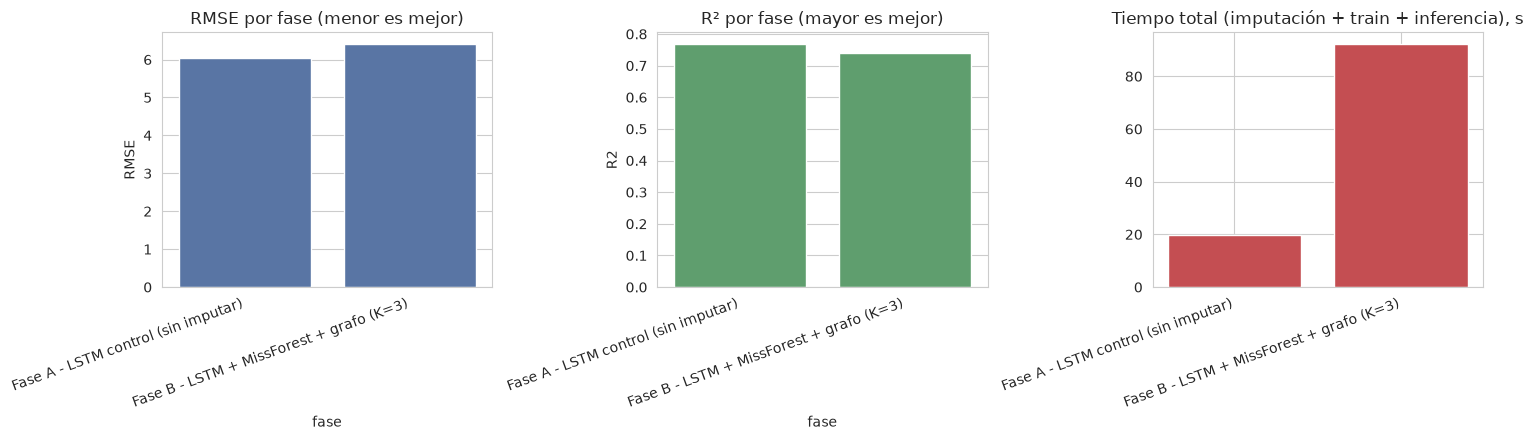

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

sns.barplot(data=tabla_resultados, x='fase', y='RMSE', ax=axes[0], color='#4C72B0')
axes[0].set_title('RMSE por fase (menor es mejor)')
axes[0].tick_params(axis='x', rotation=20)
for lbl in axes[0].get_xticklabels():
    lbl.set_ha('right')

sns.barplot(data=tabla_resultados, x='fase', y='R2', ax=axes[1], color='#55A868')
axes[1].set_title('R² por fase (mayor es mejor)')
axes[1].tick_params(axis='x', rotation=20)
for lbl in axes[1].get_xticklabels():
    lbl.set_ha('right')

tiempos_totales = (
    tabla_resultados['tiempo_imputacion_s']
    + tabla_resultados['tiempo_entrenamiento_s']
    + tabla_resultados['tiempo_inferencia_s']
)
axes[2].bar(tabla_resultados['fase'], tiempos_totales, color='#C44E52')
axes[2].set_title('Tiempo total (imputación + train + inferencia), s')
axes[2].tick_params(axis='x', rotation=20)
for lbl in axes[2].get_xticklabels():
    lbl.set_ha('right')

plt.tight_layout()
plt.show()


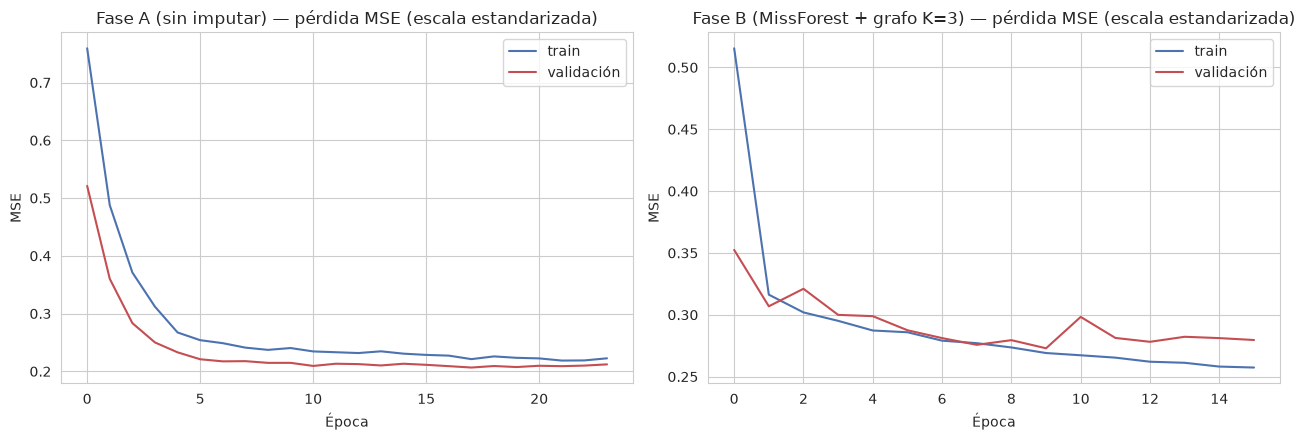

In [19]:
# ── Curvas de entrenamiento/validación de cada fase ─────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=False)

axes[0].plot(historial_a['train_loss'], label='train', color='#4C72B0')
axes[0].plot(historial_a['val_loss'], label='validación', color='#C44E52')
axes[0].set_title('Fase A (sin imputar) — pérdida MSE (escala estandarizada)')
axes[0].set_xlabel('Época')
axes[0].set_ylabel('MSE')
axes[0].legend()

axes[1].plot(historial_b['train_loss'], label='train', color='#4C72B0')
axes[1].plot(historial_b['val_loss'], label='validación', color='#C44E52')
axes[1].set_title(f'Fase B (MissForest + grafo K={K_VECINOS}) — pérdida MSE (escala estandarizada)')
axes[1].set_xlabel('Época')
axes[1].set_ylabel('MSE')
axes[1].legend()

plt.tight_layout()
plt.show()


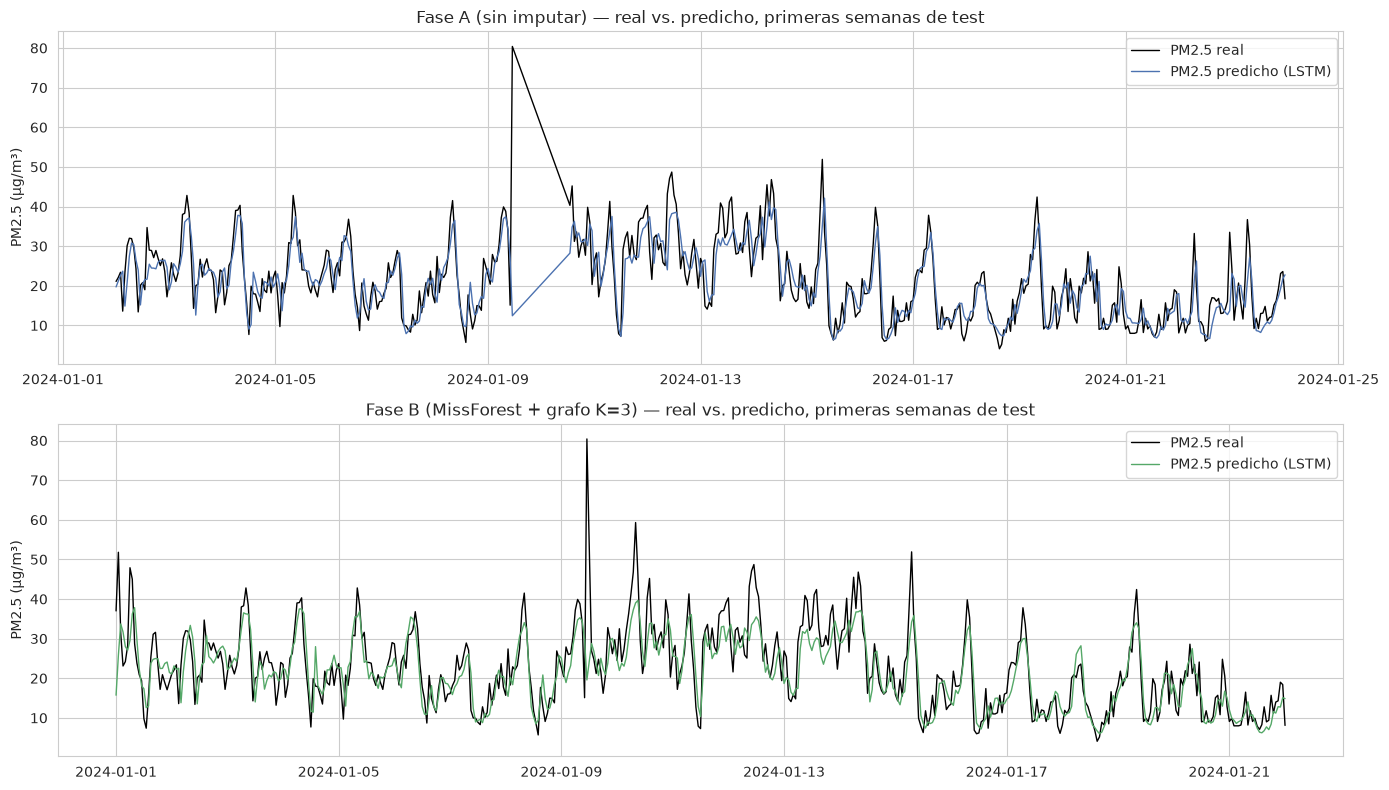

In [20]:
# ── Serie real vs. predicha en test, para cada fase ─────────────────────────
# Se grafica un recorte legible (primeras ~3 semanas de test) en vez del año
# completo, que sería ilegible como línea continua.
VENTANA_GRAFICA_HORAS = 24 * 21

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=False)

idx_a_validos = idx_test_a[ok_test_a]
recorte_a = slice(0, min(VENTANA_GRAFICA_HORAS, len(idx_a_validos)))
axes[0].plot(idx_a_validos[recorte_a], y_test_a_real[recorte_a], label='PM2.5 real', color='black', linewidth=1)
axes[0].plot(idx_a_validos[recorte_a], y_pred_a[recorte_a], label='PM2.5 predicho (LSTM)', color='#4C72B0', linewidth=1)
axes[0].set_title('Fase A (sin imputar) — real vs. predicho, primeras semanas de test')
axes[0].set_ylabel('PM2.5 (µg/m³)')
axes[0].legend()

recorte_b = slice(0, min(VENTANA_GRAFICA_HORAS, len(idx_test_b[filas_test_reales_b])))
idx_b_validos = idx_test_b[filas_test_reales_b]
axes[1].plot(idx_b_validos[recorte_b], y_test_b_real[recorte_b], label='PM2.5 real', color='black', linewidth=1)
axes[1].plot(idx_b_validos[recorte_b], y_pred_b[recorte_b], label='PM2.5 predicho (LSTM)', color='#55A868', linewidth=1)
axes[1].set_title(f'Fase B (MissForest + grafo K={K_VECINOS}) — real vs. predicho, primeras semanas de test')
axes[1].set_ylabel('PM2.5 (µg/m³)')
axes[1].legend()

plt.tight_layout()
plt.show()


### Cómo leer estas gráficas

- Si la Fase B tiene RMSE/R² claramente mejores que la Fase A, la imputación por grafo está
  aportando señal real (información espacial de las estaciones vecinas) — pero conviene revisar
  también `pct_imputado_train`: si es muy alto, parte de esa mejora puede venir de que el
  imputador "inventó" una señal fácil de aprender en horas donde faltaba casi todo, no de una
  mejora real en la capacidad predictiva.
- Si el costo de tiempo de la Fase B es mucho mayor (imputación + más features de entrada al
  LSTM) y la mejora de R² es marginal, ahí está el trade-off precisión-costo a documentar.
- En las curvas de pérdida: si `val_loss` empieza a subir mientras `train_loss` sigue bajando,
  el modelo está sobreajustando y el early stopping debería (y debió) haber cortado ahí — si no
  lo hizo, subir `PACIENCIA_EARLY_STOPPING` demasiado puede estar dejando pasar overfitting.


---

## Notas y próximos pasos

- Este cuaderno resuelve el pronóstico a **1 hora (h1)**, igual que el baseline RF. Para
  multi-paso (6/12/24/48h) habría que extender `construir_secuencias` para generar targets a
  múltiples horizontes y decidir entre pronóstico autorregresivo o multisalida directa (la
  capa `nn.Linear(hidden_size // 2, 1)` de `LSTMPronosticador` pasaría a `nn.Linear(..., H)`).
- El escalador (`StandardScaler`) se ajusta únicamente con `train` de cada fase, nunca con el
  dataset completo — así se evita fuga de información del test hacia la normalización.
- Los hiperparámetros del LSTM (`HIDDEN_SIZE`, `NUM_LAYERS`, `DROPOUT`, `LEARNING_RATE`) se
  dejaron en valores razonables por defecto, iguales entre las 2 fases para que la comparación
  sea limpia. Un ajuste de hiperparámetros (si se quiere) debe hacerse con **ventanas
  deslizantes dentro del período de train**, nunca con una partición aleatoria del 10% — mismo
  criterio que en el baseline RF.
- Si Colab se queda sin RAM/tiempo en la Fase B, los parámetros a bajar primero son los mismos
  que en el baseline RF: `N_NEAREST_FEATURES_IMPUTER`, luego `MAX_ITER_IMPUTER`, luego
  `N_ESTIMATORS_IMPUTER`; y para el LSTM, bajar `BATCH_SIZE` o `HIDDEN_SIZE` si la GPU se queda
  sin memoria.
